# Supplementary Fig. 3: Model recovery

[AI generated summary] For each model (foraging, inferential RL, standard RL; RL models with stickiness), 100 sessions of 10,000 trials are simulated with random parameters, and each simulated session is fitted with all three models (maximum likelihood). The confusion matrix shows the proportion of the simulated sessions in which each fitted model gives the best fit (highest likelihood per trial). The true model is recovered above chance level (one-sided binomial tests against 1/3, printed at the end).

**How to run:** run all cells (a few seconds). Figures are saved in `figs/`. The colormap and labels of the paper figure were edited when the figure was assembled.

**Results:** precomputed results are provided in `results/behav_modeling/recovery` (see the README). To recompute them, run in this folder: `python run_model_recovery.py` (100 simulated sessions of 10,000 trials per model, each fitted with the 3 models; ~13 h on 20 CPUs).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from popy.config import RESULTS_PATH

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

---
# Load results

In [3]:
# Load the model recovery results
results_path = os.path.join(RESULTS_PATH, "behav_modeling", "recovery", "model_recovery_10k.csv")
df = pd.read_csv(results_path)

# sort by model_true, iteration, model_fitted
df = df.sort_values(by=['model_true', 'iteration', 'model_fitted']).reset_index(drop=True)

# remove when beta < 5 or epsilon > .4
#df = df[(df["beta"] < 20) & (df["beta"] > 1)]

print(f"Loaded {len(df)} simulations")
df

Loaded 900 simulations


,model_true,model_fitted,iteration,alpha,beta,stickiness_bias,alpha_recovered,beta_recovered,stickiness_bias_recovered,LPT_best,V0,V0_recovered
0,Foraging,Foraging,0,0.429288,6.279654,NaN,0.358653,7.512074,NaN,0.511604,0.321244,0.352760
1,Foraging,Inferential RL - stickiness,0,0.429288,6.279654,NaN,0.730035,1.888728,1.576635,0.495589,0.321244,NaN
2,Foraging,Standard RL - stickiness,0,0.429288,6.279654,NaN,0.389118,2.785746,1.158414,0.464353,0.321244,NaN
3,Foraging,Foraging,1,0.350213,6.370626,NaN,0.321578,7.423149,NaN,0.686078,0.050051,0.108900
4,Foraging,Inferential RL - stickiness,1,0.350213,6.370626,NaN,0.635777,1.855338,2.821763,0.653605,0.050051,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
895,Standard RL - stickiness,Inferential RL - stickiness,98,0.371142,1.897931,1.071304,0.429187,1.204091,1.410533,0.435287,NaN,NaN
896,Standard RL - stickiness,Standard RL - stickiness,98,0.371142,1.897931,1.071304,0.675445,0.050000,1.371240,0.420998,NaN,NaN
897,Standard RL - stickiness,Foraging,99,0.213232,6.854237,0.076596,0.219369,6.396040,NaN,0.506596,NaN,0.263817
898,Standard RL - stickiness,Inferential RL - stickiness,99,0.213232,6.854237,0.076596,0.066522,8.206241,0.584239,0.543706,NaN,NaN


In [4]:
# remove all entries of WSLS
df = df[~df["model_true"].str.contains("WSLS")].reset_index(drop=True)
df = df[~df["model_fitted"].str.contains("WSLS")].reset_index(drop=True)

df

,model_true,model_fitted,iteration,alpha,beta,stickiness_bias,alpha_recovered,beta_recovered,stickiness_bias_recovered,LPT_best,V0,V0_recovered
0,Foraging,Foraging,0,0.429288,6.279654,NaN,0.358653,7.512074,NaN,0.511604,0.321244,0.352760
1,Foraging,Inferential RL - stickiness,0,0.429288,6.279654,NaN,0.730035,1.888728,1.576635,0.495589,0.321244,NaN
2,Foraging,Standard RL - stickiness,0,0.429288,6.279654,NaN,0.389118,2.785746,1.158414,0.464353,0.321244,NaN
3,Foraging,Foraging,1,0.350213,6.370626,NaN,0.321578,7.423149,NaN,0.686078,0.050051,0.108900
4,Foraging,Inferential RL - stickiness,1,0.350213,6.370626,NaN,0.635777,1.855338,2.821763,0.653605,0.050051,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
895,Standard RL - stickiness,Inferential RL - stickiness,98,0.371142,1.897931,1.071304,0.429187,1.204091,1.410533,0.435287,NaN,NaN
896,Standard RL - stickiness,Standard RL - stickiness,98,0.371142,1.897931,1.071304,0.675445,0.050000,1.371240,0.420998,NaN,NaN
897,Standard RL - stickiness,Foraging,99,0.213232,6.854237,0.076596,0.219369,6.396040,NaN,0.506596,NaN,0.263817
898,Standard RL - stickiness,Inferential RL - stickiness,99,0.213232,6.854237,0.076596,0.066522,8.206241,0.584239,0.543706,NaN,NaN


---
# Supplementary Fig. 3

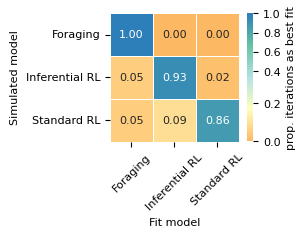

Win counts (rows=true model, cols=winning fitted model):


model_winner,Foraging,Inferential RL - stickiness,Standard RL - stickiness
model_true,,,
Foraging,100,0,0
Inferential RL - stickiness,5,93,2
Standard RL - stickiness,5,9,86


Win proportion (%):


model_winner,Foraging,Inferential RL - stickiness,Standard RL - stickiness
model_true,,,
Foraging,1.00,0.00,0.00
Inferential RL - stickiness,0.05,0.93,0.02
Standard RL - stickiness,0.05,0.09,0.86


In [5]:
# fontsize 8
plt.rcParams.update({"font.size": 8})

# For each (true model, iteration), pick the fitted model with the highest LPT_best
required_cols = {"model_true", "model_fitted", "iteration", "LPT_best"}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns in df: {sorted(missing)}")

# idx of the best-fitting model per (true model, iteration)
best_idx = df.groupby(["model_true", "iteration"])["LPT_best"].idxmax()
df_best = df.loc[best_idx, ["model_true", "model_fitted", "iteration", "LPT_best"]].copy()
df_best = df_best.rename(columns={"model_fitted": "model_winner"})

# Row-normalized counts -> percentage of wins
win_counts = pd.crosstab(df_best["model_true"], df_best["model_winner"])
win_pct = win_counts.div(win_counts.sum(axis=1), axis=0)

# Keep a consistent model ordering (if available)
model_order = sorted(pd.unique(df["model_true"]))
win_pct = win_pct.reindex(index=model_order, columns=model_order)

# Strip ' - stickiness' suffix from labels
clean_labels = [l.replace(" - stickiness", "") for l in model_order]

fig, ax = plt.subplots(figsize=(3, 3))

# Use a blue-yellow diverging colormap with enhanced contrast
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
n_models_heatmap = len(model_order)
chance_level = 1.0 / n_models_heatmap

# Get actual data range to enhance small differences
min_val = win_pct.min().min()
max_val = win_pct.max().max()

# Create custom yellow-white-blue colormap (no red)
colors_map = LinearSegmentedColormap.from_list("yellow_blue", ["#FDB863", "#FFFFBF", "#B2E2E2", "#66C2A4", "#2C7FB8"])

sns.heatmap(
    win_pct,
    annot=True,
    fmt=".2f",
    cmap=colors_map,  # Blue for high (good recovery), yellow for low (confusion)
    norm=TwoSlopeNorm(vmin=min_val, vcenter=chance_level, vmax=max_val),
    cbar_kws={"label": "prop. iterations as best fit", "shrink": 0.6},
    linewidths=0.5,
    linecolor="white",
    ax=ax,
    xticklabels=clean_labels,
    yticklabels=clean_labels,
    square=True,
)
ax.set_xlabel("Fit model")
ax.set_ylabel("Simulated model")
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()

# save as svg, transparent background, dpi 300
plt.savefig(os.path.join(FIGS_PATH, "figS3_model_recovery.svg"), format='svg', dpi=300, bbox_inches='tight')
plt.show()

print("Win counts (rows=true model, cols=winning fitted model):")
display(win_counts.reindex(index=model_order, columns=model_order).fillna(0).astype(int))

print("Win proportion (%):")
display(win_pct)

In [6]:
# Export source data (Supplementary Figure 3)
from popy.source_data import export_source_data

# heatmap values (win_pct) and the underlying counts (win_counts), rows: simulated model, columns: fitted model
counts = win_counts.reindex(index=model_order, columns=model_order).fillna(0).astype(int)
table_s3 = pd.DataFrame({'Simulated model': clean_labels})
for fit_model, label in zip(model_order, clean_labels):
    table_s3[f'Proportion of sessions best fitted by: {label}'] = win_pct[fit_model].values
for fit_model, label in zip(model_order, clean_labels):
    table_s3[f'Number of sessions best fitted by: {label}'] = counts[fit_model].values
table_s3['Number of simulated sessions'] = counts.sum(axis=1).values
export_source_data('Supplementary Figure 3', table_s3,
                   'Model recovery: for each model (rows), 100 sessions of 10,000 trials were simulated with random parameters and fitted with '
                   'all three models (maximum likelihood); proportion (heatmap values) and number of the simulated sessions in which each fitted '
                   'model (columns) had the highest likelihood per trial. No error bars.')

Supplementary Figure 3: source data saved (3 rows)


In [7]:
from scipy.stats import binomtest
from popy.config import COLORS

n_models = len(model_order)
chance = 1.0 / n_models

# Recovery rate = diagonal of win_pct
recovery_rates = np.array([win_pct.loc[m, m] if m in win_pct.columns else np.nan for m in model_order])
n_iter = win_counts.sum(axis=1).reindex(model_order).values  # total iterations per true model

# Binomial tests
binom_results = {}
print("Binomial test results (H0: recovery rate = chance = 1/n_models):")
for i, m in enumerate(model_order):
    label = m.replace(" - stickiness", "")
    k = int(win_counts.reindex(index=model_order, columns=model_order).fillna(0).loc[m, m])
    n = int(n_iter[i])
    result = binomtest(k, n, chance, alternative="greater")
    binom_results[m] = result
    print(f"  {label}: k={k}/{n}, p={result.pvalue}{' *' if result.pvalue < 0.05 else ''}")

Binomial test results (H0: recovery rate = chance = 1/n_models):
  Foraging: k=100/100, p=1.940325217482622e-48 *
  Inferential RL: k=93/100, p=4.128492812063062e-36 *
  Standard RL: k=86/100, p=1.5266862314776875e-27 *
